In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from yellowbrick.cluster import KElbowVisualizer
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline

from sklearn.model_selection import train_test_split,GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# 7. Metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 8. Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load Dataset


In [60]:
df = pd.read_csv("/content/drive/MyDrive/SI DATA SCIENTIST CAKAP/SalesStore.csv")

In [61]:
df.head()

,Order_Date,Ship_Date,Ship_Mode,Postal_Code,Region,Product_Reference,Category,Sub_Category,Sales,Quantity,Profit,State
0,2021-02-15,2021-02-20,Ground,44104,Midwest,OFF-TAP-10022901,Office Supplies,Tape,5,1,0.15,OH
1,2021-02-15,2021-02-20,Ground,44104,Midwest,OFF-TAP-10023012,Office Supplies,Tape,5,1,0.15,OH
2,2021-02-15,2021-02-20,Ground,44104,Midwest,OFF-TAP-10002828,Office Supplies,Tape,5,1,0.15,OH
3,2021-02-15,2021-02-20,Ground,44104,Midwest,OFF-TAP-10022901,Office Supplies,Tape,5,1,0.15,OH
4,2021-02-15,2021-02-20,Ground,44104,Midwest,OFF-TAP-10000482,Office Supplies,Tape,5,1,0.15,OH


## Data Understanding

In [62]:
df.shape

(216, 12)

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 216 entries, 0 to 215
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_Date         216 non-null    object 
 1   Ship_Date          216 non-null    object 
 2   Ship_Mode          216 non-null    object 
 3   Postal_Code        216 non-null    int64  
 4   Region             216 non-null    object 
 5   Product_Reference  216 non-null    object 
 6   Category           216 non-null    object 
 7   Sub_Category       216 non-null    object 
 8   Sales              216 non-null    int64  
 9   Quantity           216 non-null    int64  
 10  Profit             216 non-null    float64
 11  State              216 non-null    object 
dtypes: float64(1), int64(3), object(8)
memory usage: 20.4+ KB


In [64]:
df.describe()

,Postal_Code,Sales,Quantity,Profit
count,216.000000,216.000000,216.000000,216.000000
mean,55241.750000,290.879630,2.393519,5.843287
std,24946.773328,258.750781,1.085959,5.148745
min,20001.000000,5.000000,1.000000,0.150000
25%,33101.000000,50.000000,1.000000,1.000000
50%,60601.000000,200.000000,2.000000,4.000000
75%,75205.000000,450.000000,3.000000,9.000000
max,98101.000000,900.000000,4.000000,18.000000


In [65]:
# missing value
df.isna().sum()

,0
Order_Date,0
Ship_Date,0
Ship_Mode,0
Postal_Code,0
Region,0
Product_Reference,0
Category,0
Sub_Category,0
Sales,0
Quantity,0


## EDA

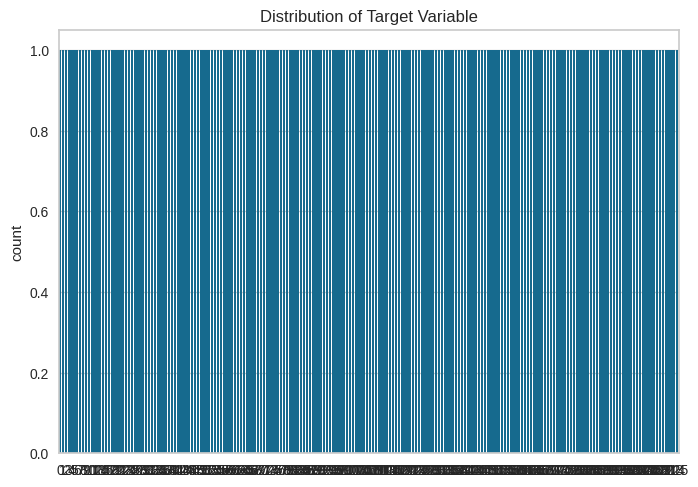

In [66]:
# distribution of is_fraud

sns.countplot(df['Sales'])
plt.title('Distribution of Target Variable')
plt.show()

<ipython-input-12-96caf4d93add>:7: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(df['state'], kde=True, color="#FF5733", palette=custom_colors)


<Axes: xlabel='state', ylabel='Count'>

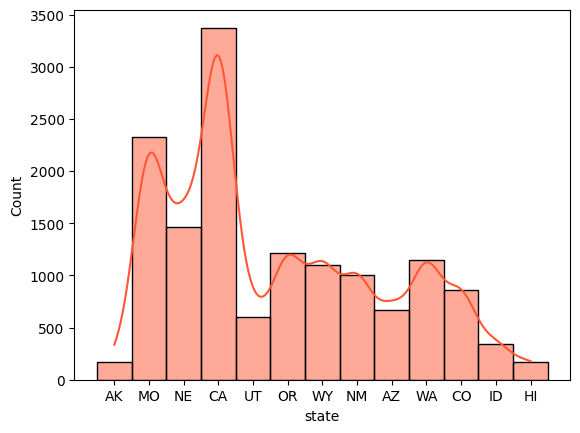

In [ ]:
# distribution of state

# Define custom colors
custom_colors = ["#FF5733", "#3366FF", "#33FF57"]  # Example colors, you can adjust as needed

# Plot the histogram with custom colors
sns.histplot(df['state'], kde=True, color="#FF5733", palette=custom_colors)

Mean 5.843287037037038
Median 4.0
Mode 0    2.0
1    6.0
Name: Profit, dtype: float64


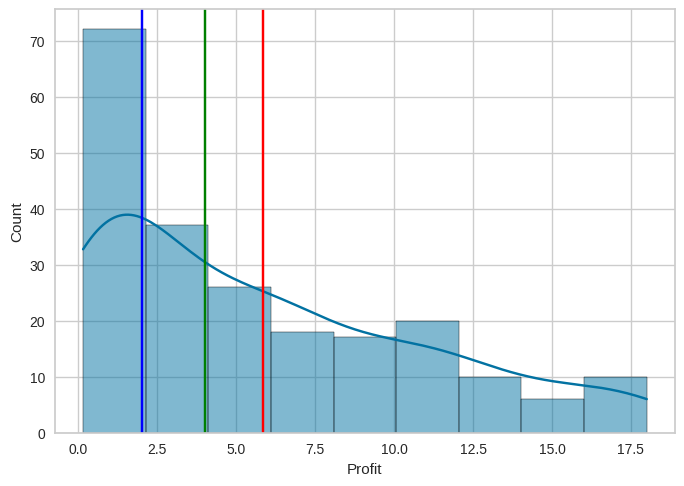

In [ ]:
# Plot the mean, Median and mode of Profit column using sns
sns.histplot(df['Profit'], kde=True)
plt.axvline(df['Profit'].mean(), color='Red')
plt.axvline(df['Profit'].median(), color= 'Green')
plt.axvline(df['Profit'].mode()[0], color='Blue')

# print the value of mean, median and mode of quality column
print('Mean', df['Profit'].mean())
print('Median', df['Profit'].median())
print('Mode', df['Profit'].mode())

In [ ]:
# plot the histogram of amt column using plotly and coloring this by is_fraud

fig = px.histogram(data_frame=df, x='Profit', color= 'Order_Date')z
fig.show()

In [ ]:
# Menghitung nilai unik dalam kolom trans_date_trans_time
unique_trans_date_trans_time = df['trans_date_trans_time'].nunique()
print(f'Jumlah kartu unik: {unique_trans_date_trans_time}')

Jumlah kartu unik: 12126


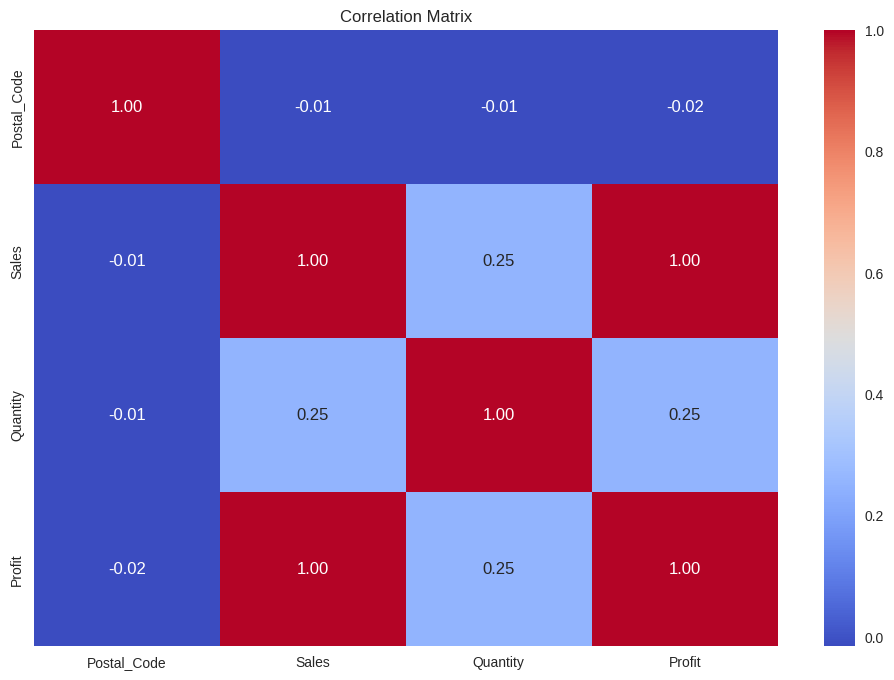

In [ ]:
numerical_features = df.select_dtypes(include=['number']).columns
correlation = df[numerical_features].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

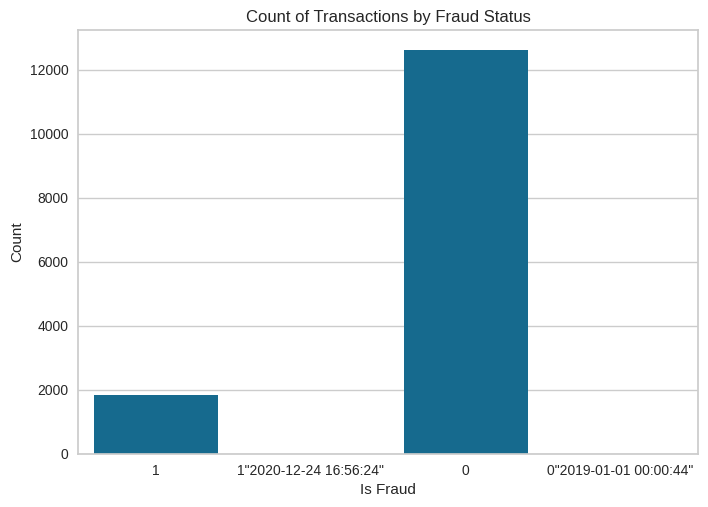

In [ ]:
# Countplot untuk kolom is_fraud
sns.countplot(x='is_fraud', data=df)
plt.title('Count of Transactions by Fraud Status')
plt.xlabel('Is Fraud')
plt.ylabel('Count')
plt.show()

## Feature Engineering

In [67]:
# Mengubah kolom tanggal menjadi datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'])

In [68]:
# Ekstraksi fitur tanggal
df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Day'] = df['Order_Date'].dt.day

df['Ship_Year'] = df['Ship_Date'].dt.year
df['Ship_Month'] = df['Ship_Date'].dt.month
df['Ship_Day'] = df['Ship_Date'].dt.day

In [69]:
# Menghitung durasi pengiriman dalam hari
df['Delivery_Duration'] = (df['Ship_Date'] - df['Order_Date']).dt.days

# Menghitung total penjualan per produk
df['Total_Sales'] = df.groupby('Product_Reference')['Sales'].transform('sum')

In [70]:
# Menampilkan beberapa kolom baru
print(df[['Order_Date', 'Ship_Date', 'Delivery_Duration', 'Total_Sales']].head())

  Order_Date  Ship_Date  Delivery_Duration  Total_Sales
0 2021-02-15 2021-02-20                  5           10
1 2021-02-15 2021-02-20                  5            5
2 2021-02-15 2021-02-20                  5            5
3 2021-02-15 2021-02-20                  5           10
4 2021-02-15 2021-02-20                  5            5


In [ ]:
# Handling Missing Values
# Select only numerical features for median imputation
numerical_features = df.select_dtypes(include=['number']).columns
df[numerical_features] = df[numerical_features].fillna(df[numerical_features].median())  # Impute missing values with median for numerical features only

TypeError: Cannot convert [['2021-02-15' '2021-02-15' '2021-02-15' ... '2024-01-09' '2024-01-09'
  '2024-01-09']
 ['2021-02-20' '2021-02-20' '2021-02-20' ... '2024-01-14' '2024-01-14'
  '2024-01-14']
 ['Ground' 'Ground' 'Ground' ... 'Ground' 'Ground' 'Ground']
 ...
 ['Office Supplies' 'Office Supplies' 'Office Supplies' ... 'Electronics'
  'Electronics' 'Electronics']
 ['Tape' 'Tape' 'Tape' ... 'Printers' 'Printers' 'Printers']
 ['OH' 'OH' 'OH' ... 'DC' 'DC' 'DC']] to numeric

In [73]:
# Splitting the data into train and test sets
X = df.drop('Delivery_Duration', axis=1)
y = df['Delivery_Duration']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Modeling


In [79]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Create a LabelEncoder object
le = LabelEncoder()

# List of categorical features to encode
categorical_features = ['Ship_Mode', 'State',
                       'Region', 'Category', 'Sub-Category']

# Check if all categorical_features are in X_train
for feature in categorical_features:
    if feature not in X_train.columns:
        print(f"Warning: Feature '{feature}' not found in X_train. Skipping.")
        continue  # Skip to the next feature if not found

    # Encode categorical features in both training and testing sets
    X_train[feature] = le.fit_transform(X_train[feature])
    X_test[feature] = le.transform(X_test[feature])  # Use transform, not fit_transform, for the test set


# Now you can proceed with model training
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

ValueError: could not convert string to float: 'ELE-MON-10000472'

In [76]:
from sklearn.ensemble import RandomForestClassifier

# Convert 'Order_Date' and 'Ship_Date' to numerical features
# calculate the time difference between these dates in days
# and use this difference as a numerical feature
X_train['Order_Date'] = pd.to_numeric(pd.to_datetime(X_train['Order_Date']))
X_train['Ship_Date'] = pd.to_numeric(pd.to_datetime(X_train['Ship_Date']))

X_test['Order_Date'] = pd.to_numeric(pd.to_datetime(X_test['Order_Date']))
X_test['Ship_Date'] = pd.to_numeric(pd.to_datetime(X_test['Ship_Date']))


# model training
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

ValueError: could not convert string to float: 'Ground'

In [74]:
# Train a Random Forest Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

NameError: name 'RandomForestClassifier' is not defined

In [ ]:
# Convert is_fraud to numeric, forcing errors to NaN
df['is_fraud'] = pd.to_numeric(df['is_fraud'], errors='coerce')

# Drop rows with NaN in is_fraud
df = df.dropna(subset=['is_fraud'])

# Now filter again
df_majority = df[df['is_fraud'] == 0]
df_minority = df[df['is_fraud'] == 1]

# Check sizes
print(f'Jumlah baris dalam df_majority: {len(df_majority)}')
print(f'Jumlah baris dalam df_minority: {len(df_minority)}')

Jumlah baris dalam df_majority: 12600
Jumlah baris dalam df_minority: 1844


In [ ]:
# Check the unique values in is_fraud
print("Unique values in is_fraud:", df['is_fraud'].unique())

# Convert is_fraud to numeric, forcing errors to NaN
df['is_fraud'] = pd.to_numeric(df['is_fraud'], errors='coerce')

# Drop rows with NaN in is_fraud
df = df.dropna(subset=['is_fraud'])

# Split into majority and minority classes
df_majority = df[df['is_fraud'] == 0]
df_minority = df[df['is_fraud'] == 1]

# Check sizes after filtering
print(f'Jumlah baris dalam df_majority: {len(df_majority)}')
print(f'Jumlah baris dalam df_minority: {len(df_minority)}')

# Print samples from both classes
print("Majority class samples:")
print(df_majority.head())
print("Minority class samples:")
print(df_minority.head())

# Perform upsampling if the minority class is not empty
if len(df_minority) > 0:
    df_minority_upsampled = resample(df_minority,
                                      replace=True,
                                      n_samples=len(df_majority),
                                      random_state=42)

    # Combine back to form a balanced dataset
    df_upsampled = pd.concat([df_majority, df_minority_upsampled])
    print(f'Jumlah baris dalam df_upsampled: {len(df_upsampled)}')
else:
    print("No samples in minority class to upsample.")

Unique values in is_fraud: [1. 0.]
Jumlah baris dalam df_majority: 12600
Jumlah baris dalam df_minority: 1844
Majority class samples:
     trans_date_trans_time                                merchant  \
1782      24-12-2020 16:58           "Hahn, Douglas and Schowalte"   
1783      24-12-2020 16:59                           Erdman-Durgan   
1784      24-12-2020 16:59         "Prosacco, Kreiger and Kovacek"   
1785      24-12-2020 16:59  "Romaguera, Cruickshank and Greenholt"   
1786      24-12-2020 17:00                      Spencer-Runolfsson   

            category     amt        city state      lat      long  city_pop  \
1782          travel  440.56   Meadville    MO  39.7795  -93.3014       964   
1783  health_fitness   60.39  Crownpoint    NM  35.7206 -108.0271      5662   
1784            home   16.13  Mound City    MO  40.1362  -95.2138      1631   
1785    shopping_net    6.70        Napa    CA  38.4549 -122.2564     94014   
1786        misc_pos   55.61   Hawthorne    CA  33

In [ ]:

# 1. Identify columns with date/time strings:
#   (You might need to adjust this based on your actual column names)
datetime_cols = ['trans_date_trans_time']  # Replace with your actual datetime columns

# 2. Convert datetime columns to numerical representation:
for col in datetime_cols:
    # a. Convert to datetime objects
    df_upsampled[col] = pd.to_datetime(df_upsampled[col])
    # b. Extract numerical features (e.g., hour, day, month)
    df_upsampled[col + '_hour'] = df_upsampled[col].dt.hour
    df_upsampled[col + '_day'] = df_upsampled[col].dt.day
    df_upsampled[col + '_month'] = df_upsampled[col].dt.month
    # c. Drop the original datetime column
    df_upsampled = df_upsampled.drop(col, axis=1)

# 3. Handle other categorical features:
categorical_cols = df_upsampled.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if col != 'is_fraud': # Exclude target variable
        le = LabelEncoder()
        df_upsampled[col] = le.fit_transform(df_upsampled[col])

In [ ]:
# Split the data
X = df_upsampled.drop('is_fraud', axis=1)
y = df_upsampled['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Train a Random Forest Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
# Predictions
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

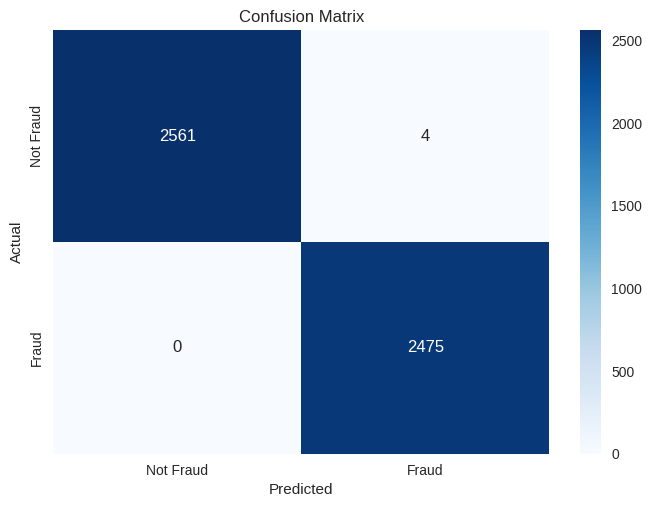

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      2565
         1.0       1.00      1.00      1.00      2475

    accuracy                           1.00      5040
   macro avg       1.00      1.00      1.00      5040
weighted avg       1.00      1.00      1.00      5040



In [ ]:
# AUC-ROC Score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print("ROC-AUC Score: ", roc_auc)

ROC-AUC Score:  0.9999995274381239


## Interpretasi Hasil:
1. Dengan upsampling, distribusi kelas menjadi seimbang, yang membantu model mempelajari pola dari kedua kelas secara setara.
2. Evaluasi dengan ROC-AUC menunjukkan kemampuan model untuk membedakan antara kelas positif dan negatif.
3. Pada Classification Report, perhatikan metrik seperti Precision, Recall, dan F1-score untuk kelas minoritas, karena itu adalah fokus utama.
4. Perbaikan dari baseline (data tidak diimbangi) akan menunjukkan manfaat penanganan imbalance data.